# Week 5 — Simple Model Comparison

Train Decision Tree and Random Forest regressors, compare their test R² with
the saved Linear Regression baseline, and document model behavior.

Run Notebook 02 and Notebook 03 first. Use the same four prepared CSVs that
were used to create `baseline_results.csv`. 

## 1. Import libraries

Load pandas, the two additional regressors, and the R² metric.

In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

## 2. Load the prepared data and saved baseline

Use the existing training/test files without changing the rows or their order.
Load the Linear Regression score recorded by Notebook 03.

In [2]:
X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")
y_train = pd.read_csv("../data/processed/y_train.csv")["ClosePrice"]
y_test = pd.read_csv("../data/processed/y_test.csv")["ClosePrice"]

baseline_results = pd.read_csv("../data/processed/baseline_results.csv")
baseline = baseline_results.loc[
    baseline_results["Model"].eq("Linear Regression")
].iloc[0]
baseline_r2 = baseline["Test_R2"]

print(f"Linear Regression baseline R²: {baseline_r2:.4f}")

Linear Regression baseline R²: 0.8159


## 3. Sanity checks

Check aligned input/target lengths, identical feature columns, and no missing
predictors. Compare dataset sizes with the saved baseline metadata to catch an
obviously stale baseline. These size checks cannot prove that the same records
were used; keep the original CSVs unchanged for the comparison.

In [3]:
assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)
assert X_train.columns.equals(X_test.columns)
assert not X_train.isna().any().any()
assert not X_test.isna().any().any()
assert len(X_train) == baseline["TrainingRows"]
assert len(X_test) == baseline["TestRows"]
assert X_train.shape[1] == baseline["PredictorColumns"]

print("Data checks passed.")

Data checks passed.


## 4. Train and evaluate Decision Tree

A Decision Tree learns splits such as area or location thresholds. Limit depth
to 18 and require at least five training records per leaf to restrain complexity.
These are initial fixed settings, not tuned values. `random_state=42` makes the
experiment repeatable. Compare training and test R² to help recognize overfitting.

In [4]:
tree_model = DecisionTreeRegressor(
    max_depth=18,
    min_samples_leaf=5,
    random_state=42
)

tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_test)

tree_train_r2 = tree_model.score(X_train, y_train)
tree_test_r2 = r2_score(y_test, tree_predictions)

print(f"Decision Tree training R²: {tree_train_r2:.4f}")
print(f"Decision Tree test R²: {tree_test_r2:.4f}")

Decision Tree training R²: 0.9208
Decision Tree test R²: 0.8025


## 5. Train and evaluate Random Forest

Random Forest averages the predictions of 100 trees. This can reduce the
instability of a single tree, but requires more computation. Use the same depth
and leaf limits, a fixed seed, and available CPU cores for parallel training.
The test data is passed only to predict/evaluate, not to fit.

In [5]:
forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=18,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_test)

forest_train_r2 = forest_model.score(X_train, y_train)
forest_test_r2 = r2_score(y_test, forest_predictions)

print(f"Random Forest training R²: {forest_train_r2:.4f}")
print(f"Random Forest test R²: {forest_test_r2:.4f}")

Random Forest training R²: 0.9264
Random Forest test R²: 0.8674


## 6. Compare against the baseline and save results

Higher test R² is better. A positive change means a higher R² than the saved
Linear Regression baseline on this test set. The change is an absolute R²
difference, not a percentage of correctly priced properties.

In [6]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "Test_R2": [baseline_r2, tree_test_r2, forest_test_r2]
})

comparison["ChangeFromBaseline"] = comparison["Test_R2"] - baseline_r2

display(comparison.round(4))
comparison.to_csv("../data/processed/model_comparison.csv", index=False)

,Model,Test_R2,ChangeFromBaseline
0,Linear Regression,0.8159,0.0000
1,Decision Tree,0.8025,-0.0134
2,Random Forest,0.8674,0.0515


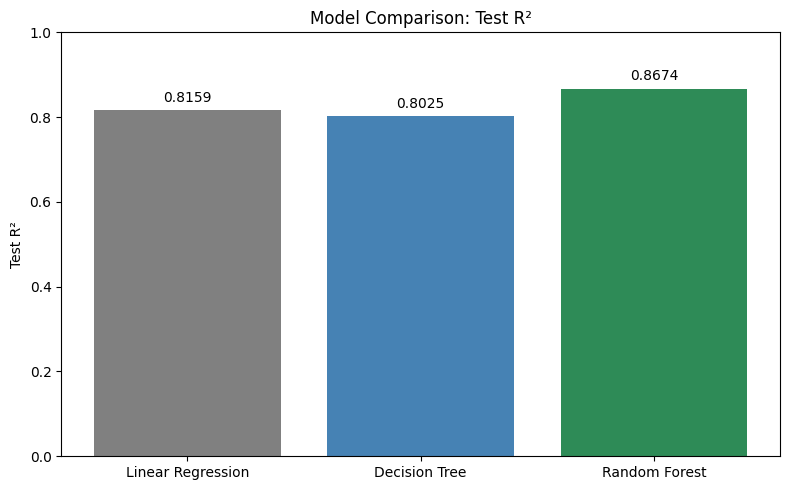

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    comparison["Model"],
    comparison["Test_R2"],
    color=["gray", "steelblue", "seagreen"]
)

# Display the R² score above each bar
ax.bar_label(bars, fmt="%.4f", padding=4)

ax.set_title("Model Comparison: Test R²")
ax.set_ylabel("Test R²")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

## 7. Model comparison and findings

Three models were evaluated using the same training and test sets.

- **Linear Regression:** achieved a test R² of **0.8159**, serving as the
  baseline for comparison.

- **Decision Tree:** achieved a training R² of **0.9208** and a test R²
  of **0.8025**, slightly below the baseline. The gap between training
  and test performance suggests possible overfitting: the model learned
  patterns in the training data that did not transfer as well to unseen
  properties.

- **Random Forest:** achieved a training R² of **0.9264** and a test R²
  of **0.8674**, outperforming the baseline by **0.0515**. Its smaller
  training/test gap suggests better generalization than the single
  Decision Tree. Averaging predictions from many trees helps reduce
  sensitivity to individual training examples, although training takes longer.

**Random Forest performed best on this test set.** The Decision Tree's
high training score did not translate into better test predictions,
showing why models should be compared using their test performance.

These results use the initial model settings; hyperparameters have
not yet been optimized.